# Lab 3: Value Function Iteration

Open this project folder in **VS Code** and follow [README.md](README.md) for setup. Run the notebook from top to bottom.

`mdp.py` defines the input format. The three model files build the inputs; `vfi.py` contains the only VFI algorithm. This notebook imports those files and displays the results.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from maze import Maze
from mccall import McCallModel
from saving import ConsumptionSavingModel
from vfi import value_iteration, simulate_policy
from figures import (plot_maze, plot_convergence, plot_mccall,
                     plot_saving, plot_saving_rollout)

np.set_printoptions(precision=4, suppress=True)

## The shared MDP input

Each model inherits the same `MDP` container. Python row `i` represents state $s_i$; column `j` represents a possible action.

| Attribute | Meaning |
|---|---|
| `states[i]` | State label |
| `actions[i, j]` | Actual action at that row and column |
| `feasible[i, j]` | Whether this action is allowed |
| `rewards[i, j]` | Reward $r(s_i,a_j)$ |
| `P[i, j, next_i]` | Transition probability to the next state |
| `beta` | Discount factor |

In `vfi.py`, `P @ V` takes the probability-weighted sum over next states:

$$Q_k(s,a)=r(s,a)+\beta\sum_{s'}P(s'\mid s,a)V_k(s'),\qquad V_{k+1}(s)=\max_a Q_k(s,a).$$

The code follows Steps 0–7 of the lecture algorithm. `value_iteration(model)` starts at zero. To supply a value vector, use `value_iteration(model, initial_V=V0)`. The returned dictionary includes `values`, `policy`, and convergence diagnostics.

## 1. Maze

Use the lecture maze with $\beta=0.9$. Each move costs $1$, including entry into the absorbing goal; later rewards are zero. The start is cell 16 and the goal is cell 8. Python index `i` corresponds to lecture cell `i + 1`. Action codes 0, 1, 2, 3 mean U, D, L, R.

In [2]:
maze = Maze(beta=0.9)
print("Reward table:", maze.rewards.shape)
print("Transition table:", maze.P.shape)

# Inspect the MDP input for the action R at the start.
i, j = maze.start, 3
print("Reward:", maze.rewards[i, j])
print("Possible next cells:", np.flatnonzero(maze.P[i, j]) + 1)
print("Their probabilities:", maze.P[i, j, maze.P[i, j] > 0])

Reward table: (47, 4)
Transition table: (47, 4, 47)
Reward: -1.0
Possible next cells: [17]
Their probabilities: [1.]


Value at start: -7.7123207545039
Moves to goal: 14
Path (lecture cell numbers): [16, 23, 31, 32, 33, 34, 25, 26, 27, 28, 29, 30, 22, 15, 8]


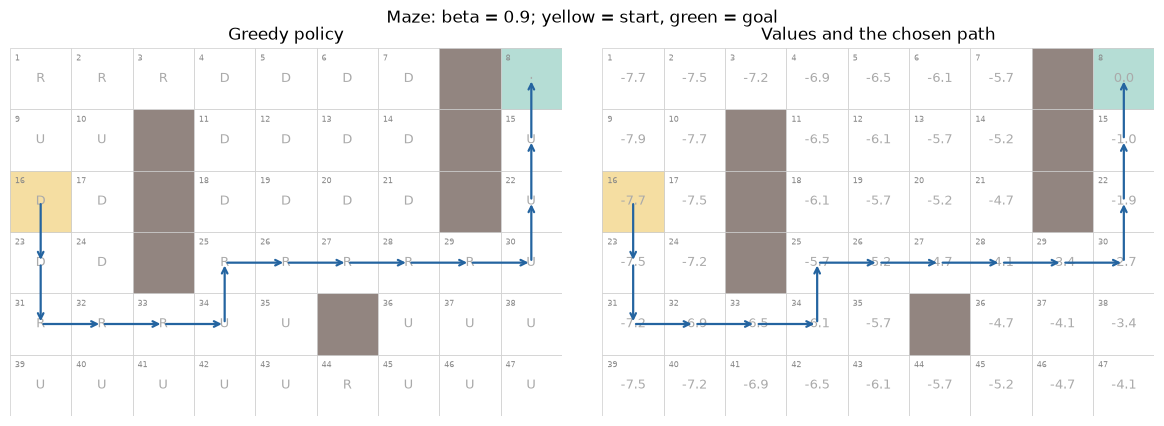

In [3]:
maze_result = value_iteration(maze)
path = maze.path(maze_result["policy"])
print("Value at start:", maze_result["values"][maze.start])
print("Moves to goal:", len(path) - 1)
print("Path (lecture cell numbers):", [int(i) + 1 for i in path])
plot_maze(maze, maze_result)
plt.show()

### Watch values propagate

`history[k]` stores $V_k$. The final corridor is 30 → 22 → 15 → 8.

Columns: cells 30, 22, 15, 8
V_0: [0. 0. 0. 0.]
V_1: [-1. -1. -1.  0.]
V_2: [-1.9 -1.9 -1.   0. ]
V_3: [-2.71 -1.9  -1.    0.  ]


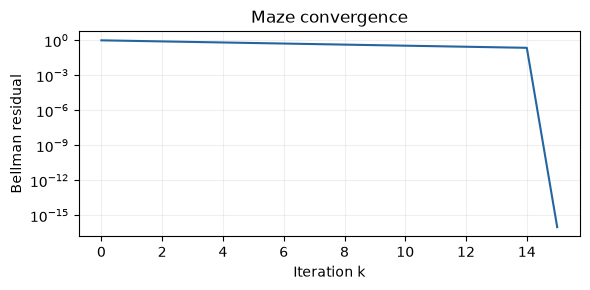

In [4]:
corridor = np.array([30, 22, 15, 8]) - 1
print("Columns: cells 30, 22, 15, 8")
for k in range(4):
    print(f"V_{k}:", maze_result["history"][k, corridor])
plot_convergence(maze_result, "Maze convergence")
plt.show()

## 2. McCall job search

The state is $(U,w)$ or $(E,w)$. Accepting pays $w$ now and leads to permanent employment at $w$. Rejecting pays $b$ and draws another offer with probabilities $q$.

$$V_{k+1}((U,w))=\max\left\{w+\beta V_k((E,w)),\ b+\beta\sum_{w'}q(w')V_k((U,w'))\right\},$$
$$V_{k+1}((E,w))=w+\beta V_k((E,w)).$$

`mccall.py` supplies the reward and transition tables. The same solver starts **all** state values at zero.

('U', 1.0) value: 34.3243 action: reject
('U', 2.0) value: 34.3243 action: reject
('U', 3.0) value: 34.3243 action: reject
('U', 4.0) value: 40.0 action: accept
('U', 5.0) value: 50.0 action: accept


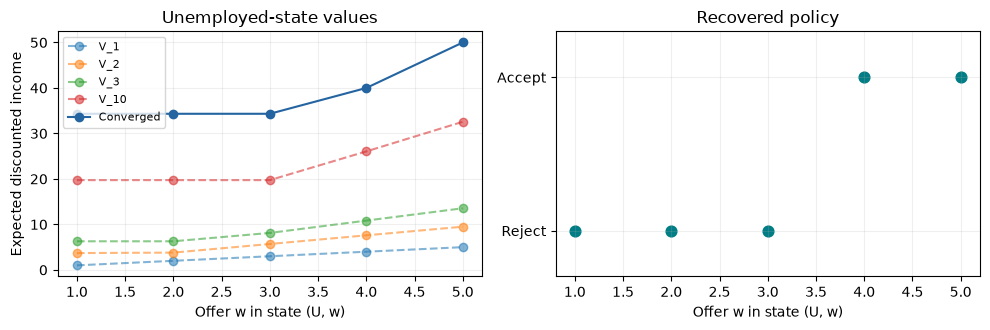

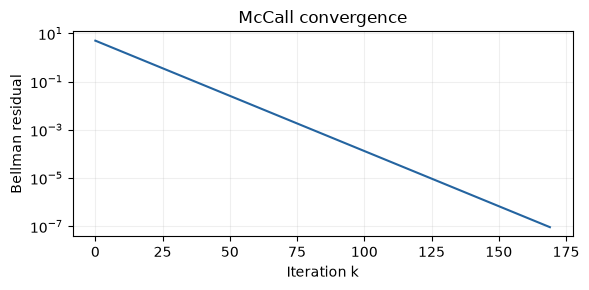

In [5]:
search = McCallModel(benefit=1.0, beta=0.9)
search_result = value_iteration(search)
for i in range(search.n):
    print(search.states[i], "value:", round(search_result["values"][i], 4),
          "action:", search_result["policy"][i])
plot_mccall(search, search_result)
plot_convergence(search_result, "McCall convergence")
plt.show()

### Supply an initial value vector

Employed-state values are known: $V^*((E,w))=w/(1-\beta)$. Initialize those entries at their exact values, leave the unemployed entries at zero, and rerun the same solver.

In [6]:
V0 = np.zeros(len(search.states))
V0[search.n:] = search.wages / (1 - search.beta)
initialized_result = value_iteration(search, initial_V=V0)
print("Bellman evaluations from zero:", search_result["iterations"])
print("Bellman evaluations with supplied V0:", initialized_result["iterations"])
print("Largest final value difference:",
      np.max(np.abs(search_result["values"] - initialized_result["values"])))
print("Same policy:", np.array_equal(search_result["policy"], initialized_result["policy"]))

Bellman evaluations from zero: 170
Bellman evaluations with supplied V0: 40
Largest final value difference: 9.246004566421107e-07
Same policy: True


### Change the benefit

Raise the benefit and solve again. Only the model inputs change.

In [7]:
higher_benefit = McCallModel(benefit=4.0, beta=0.9)
higher_result = value_iteration(higher_benefit)
for i in range(search.n):
    print(search.states[i], "b=1:", search_result["policy"][i],
          "b=4:", higher_result["policy"][i])

('U', 1.0) b=1: reject b=4: reject
('U', 2.0) b=1: reject b=4: reject
('U', 3.0) b=1: reject b=4: reject
('U', 4.0) b=1: accept b=4: reject
('U', 5.0) b=1: accept b=4: accept


### Simulate the recovered policy

As in Lab 2, a policy function maps the current state to an action. The simulation uses the model's `step` method.

In [8]:
def search_policy(state):
    return search_result["policy"][state]

path, rewards = simulate_policy(search, search_policy, initial_state=1, periods=12, seed=7)
print("States:", [search.states[i] for i in path])
print("Rewards:", rewards)

States: [('U', 2.0), ('U', 3.0), ('U', 4.0), ('E', 4.0), ('E', 4.0), ('E', 4.0), ('E', 4.0), ('E', 4.0), ('E', 4.0), ('E', 4.0), ('E', 4.0), ('E', 4.0), ('E', 4.0)]
Rewards: [1. 1. 4. 4. 4. 4. 4. 4. 4. 4. 4. 4.]


## 3. Continuous consumption-saving

Stock is $s\in[0,M+B]$. Save $a\in[0,\min(s,M)]$, consume $s-a$, and draw $Y'\sim\mathrm{Uniform}[0,B]$. Next stock is $s'=a+Y'$; reward is $(s-a)^\alpha$.

$$V_{k+1}(s)=\max_{0\leq a\leq\min(s,M)}\left\{(s-a)^\alpha+\frac{\beta}{B}\int_0^B V_k(a+y)\,dy\right\}.$$

`saving.py` converts this continuous problem to a **numerical MDP**:

- Store values on a stock grid and consider a grid of feasible saving choices.
- Approximate the income average with equally weighted midpoint draws.
- Split each off-grid next stock between its two neighboring grid points. These interpolation weights form `P`.

Then `P @ V` computes the average interpolated continuation value, and the same VFI solver applies.

Transition table: (101, 81, 101)
Numerical-MDP value error bound: 9.66462458507067e-06


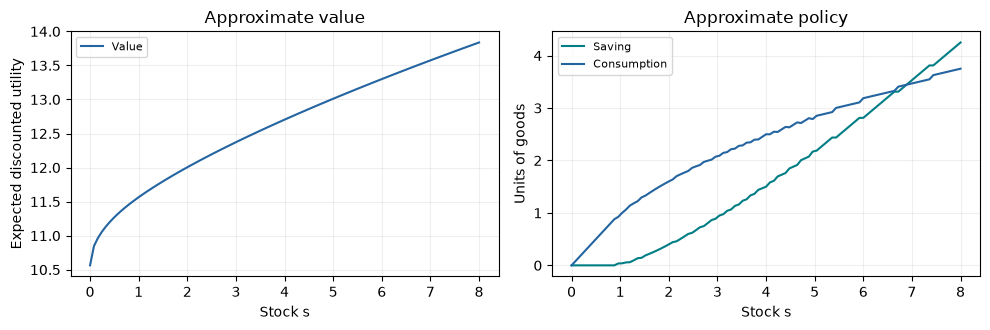

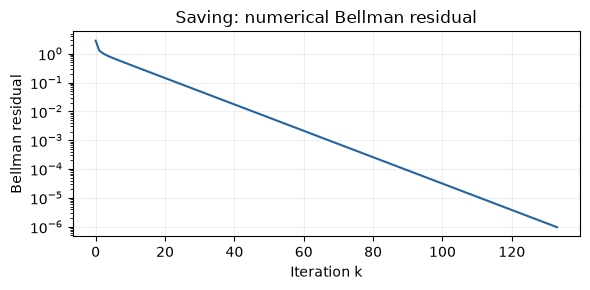

In [9]:
saving = ConsumptionSavingModel(M=5, B=3, alpha=0.5, beta=0.9)
saving_result = value_iteration(saving, tolerance=1e-5)
print("Transition table:", saving.P.shape)
print("Numerical-MDP value error bound:", saving_result["error_bound"])
plot_saving(saving, saving_result)
plot_convergence(saving_result, "Saving: numerical Bellman residual")
plt.show()

### Refine the approximation

A small residual controls iteration error for the supplied numerical MDP. Compare finer grids to assess the separate discretization and integration errors.

Largest value difference on baseline points: 0.0026763881026781178


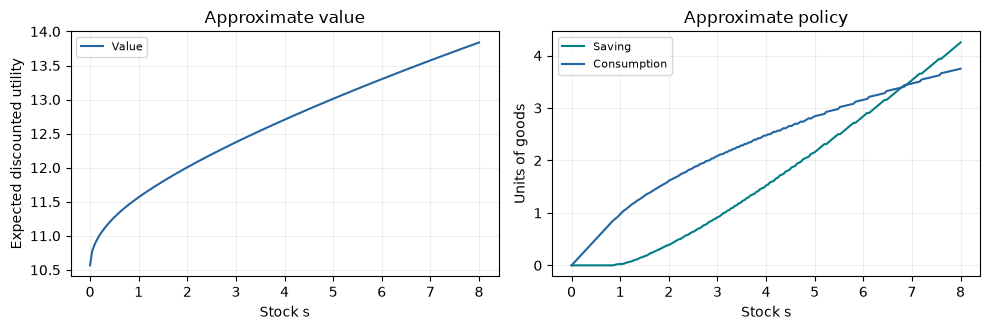

In [10]:
finer = ConsumptionSavingModel(n_states=201, n_actions=161, n_income=81)
finer_result = value_iteration(finer, tolerance=1e-5)
finer_values_at_old_points = np.interp(saving.states, finer.states, finer_result["values"])
print("Largest value difference on baseline points:",
      np.max(np.abs(saving_result["values"] - finer_values_at_old_points)))
plot_saving(finer, finer_result)
plt.show()

### Simulate the continuous model

Interpolate the saving policy between stock points. Simulation draws income from the original continuous distribution.

Mean realized utility on this path: 1.2566066557328108


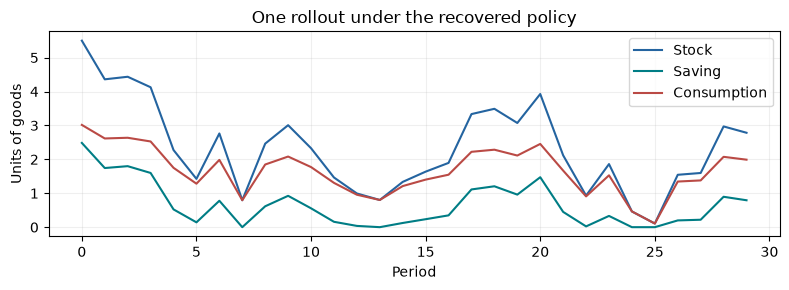

In [11]:
def saving_policy(stock):
    return np.interp(stock, saving.states, saving_result["policy"])

stocks, rewards = simulate_policy(saving, saving_policy, initial_state=5.5,
                                  periods=30, seed=7)
actions = np.array([saving_policy(s) for s in stocks[:-1]])
print("Mean realized utility on this path:", rewards.mean())
plot_saving_rollout(stocks, actions)
plt.show()

## Solver performance

Compare Bellman evaluations, runtime, and the final value-error bound. Runtime measures the solver only; building each model's input tables is excluded. For saving, the bound applies to the numerical MDP. Timings vary by computer.

In [12]:
runs = {"Maze": maze_result, "McCall": search_result, "Saving": saving_result}
print(f"{'Model':<12} {'Evaluations':>12} {'Seconds':>12} {'Value bound':>14}")
for name, result in runs.items():
    print(f"{name:<12} {result['iterations']:>12} {result['seconds']:>12.4f} "
          f"{result['error_bound']:>14.3e}")

Model         Evaluations      Seconds    Value bound
Maze                   16       0.0001      0.000e+00
McCall                170       0.0006      9.246e-07
Saving                134       0.0055      9.665e-06


## References

1. **Richard S. Sutton and Andrew G. Barto (2018), *Reinforcement Learning: An Introduction*. 2nd ed. MIT Press.** [Chapter 3: Finite Markov Decision Processes](https://www.andrew.cmu.edu/course/10-703/textbook/BartoSutton.pdf#page=69); [Chapter 4: Dynamic Programming](https://www.andrew.cmu.edu/course/10-703/textbook/BartoSutton.pdf#page=95).
2. **Thomas J. Sargent and John Stachurski, QuantEcon.** [Discrete State Dynamic Programming: Value Function Iteration](https://tools-techniques.quantecon.org/discrete_dp.html#value-function-iteration); [Job Search I: The McCall Search Model](https://python.quantecon.org/mccall_model.html#the-mccall-model); [Discrete State Dynamic Programming: Example—A Growth Model](https://tools-techniques.quantecon.org/discrete_dp.html#example-a-growth-model).

The consumption-saving model extends the bounded-storage example to continuous stock, saving, and uniform income.